<a href="https://colab.research.google.com/github/NethsanduKumarasinghe/EN3160_Assignment_03/blob/main/EN3160_Assignment_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [2]:


# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

KeyboardInterrupt: 

In [4]:
# 2. Define Network Parameters

Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100             # Number of hidden neurons
K = 10              # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 1e-2
lr_decay = 0.9
reg = 0
loss_history = []

In [5]:
# 3. Training Loop

for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)
        y_pred = h.mm(w2) + b2

        # Loss calculation
        loss = nn.functional.cross_entropy(y_pred, labels)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = torch.softmax(y_pred, dim=1)
        dy_pred[torch.arange(Ntr), labels] -= 1
        dy_pred /= Ntr

        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        dh = dy_pred.mm(w2.t())
        dz1 = dh * h * (1 - h)

        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        with torch.no_grad():
            w1 -= lr * dw1
            b1 -= lr * db1
            w2 -= lr * dw2
            b2 -= lr * db2

    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, "
            f"Loss: {running_loss / len(trainloader):.4f}"
        )

    # Learning rate decay
    lr *= lr_decay

Epoch 1/10, Loss: 2.3037
Epoch 2/10, Loss: 2.2917
Epoch 3/10, Loss: 2.1537
Epoch 4/10, Loss: 2.0790
Epoch 5/10, Loss: 2.0453
Epoch 6/10, Loss: 2.0058
Epoch 7/10, Loss: 1.9730
Epoch 8/10, Loss: 1.9487
Epoch 9/10, Loss: 1.9311
Epoch 10/10, Loss: 1.9176


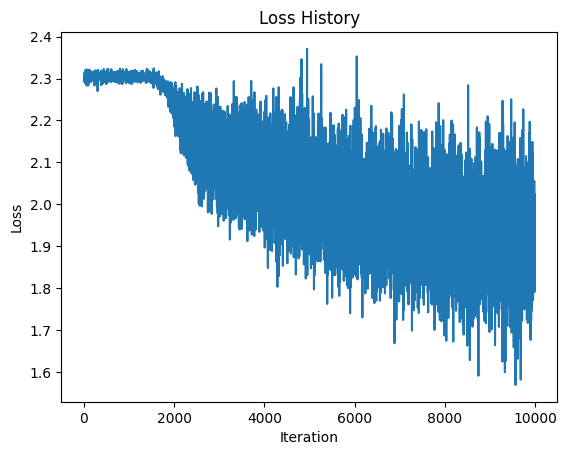

In [6]:
# 4. Plotting the Loss History

plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [7]:
# 5. Calculate Accuracy on Training Set

correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)
        y_train_pred = h.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train

print(f"Training accuracy: {train_acc:.2f}%")

Training accuracy: 30.55%


In [8]:
# 6. Calculate Accuracy on Test Set

correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        z1 = x_test.mm(w1) + b1
        h = torch.sigmoid(z1)
        y_test_pred = h.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test

print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 30.90%


Question 2: CNNs for MNIST
2(a). LeNet-5

In [9]:
# 1. Dataloading

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64

trainset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 508kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.55MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.50MB/s]


In [14]:
# 2. Define LeNet-5
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()

        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)

        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(torch.tanh(self.conv1(x)))
        x = self.pool(torch.tanh(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.fc3(x)

        return x

In [15]:
model_lenet = LeNet5().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_lenet.parameters(), lr=0.001)

epochs = 10

In [16]:
# 3. Training Loop

train_losses_lenet = []
test_losses_lenet = []
train_accs_lenet = []
test_accs_lenet = []

for epoch in range(epochs):
    model_lenet.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model_lenet(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        predicted = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    model_lenet.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model_lenet(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            predicted = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss /= total
    test_acc = 100 * correct / total

    train_losses_lenet.append(train_loss)
    test_losses_lenet.append(test_loss)
    train_accs_lenet.append(train_acc)
    test_accs_lenet.append(test_acc)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch 1/10 | Train Loss: 0.2594 | Train Acc: 92.77% | Test Loss: 0.0859 | Test Acc: 97.28%
Epoch 2/10 | Train Loss: 0.0746 | Train Acc: 97.71% | Test Loss: 0.0556 | Test Acc: 98.24%
Epoch 3/10 | Train Loss: 0.0513 | Train Acc: 98.41% | Test Loss: 0.0506 | Test Acc: 98.38%
Epoch 4/10 | Train Loss: 0.0401 | Train Acc: 98.75% | Test Loss: 0.0464 | Test Acc: 98.53%
Epoch 5/10 | Train Loss: 0.0327 | Train Acc: 98.98% | Test Loss: 0.0434 | Test Acc: 98.68%
Epoch 6/10 | Train Loss: 0.0267 | Train Acc: 99.15% | Test Loss: 0.0427 | Test Acc: 98.70%
Epoch 7/10 | Train Loss: 0.0240 | Train Acc: 99.24% | Test Loss: 0.0368 | Test Acc: 98.95%
Epoch 8/10 | Train Loss: 0.0200 | Train Acc: 99.31% | Test Loss: 0.0370 | Test Acc: 98.89%
Epoch 9/10 | Train Loss: 0.0156 | Train Acc: 99.53% | Test Loss: 0.0414 | Test Acc: 98.77%
Epoch 10/10 | Train Loss: 0.0148 | Train Acc: 99.55% | Test Loss: 0.0358 | Test Acc: 98.97%


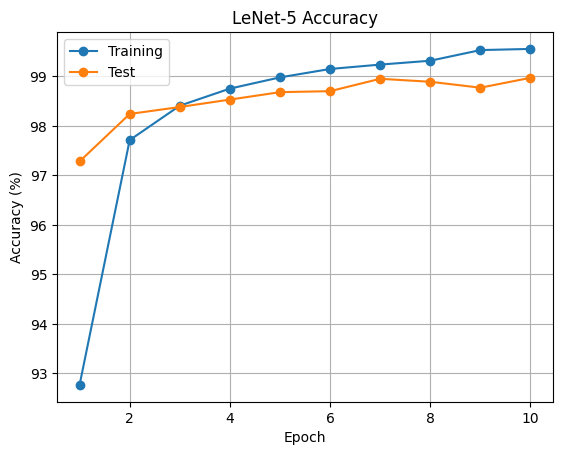

In [17]:
plt.plot(range(1, epochs + 1), train_accs_lenet, marker='o', label='Training')
plt.plot(range(1, epochs + 1), test_accs_lenet, marker='o', label='Test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('LeNet-5 Accuracy')
plt.legend()
plt.grid(True)
plt.show()

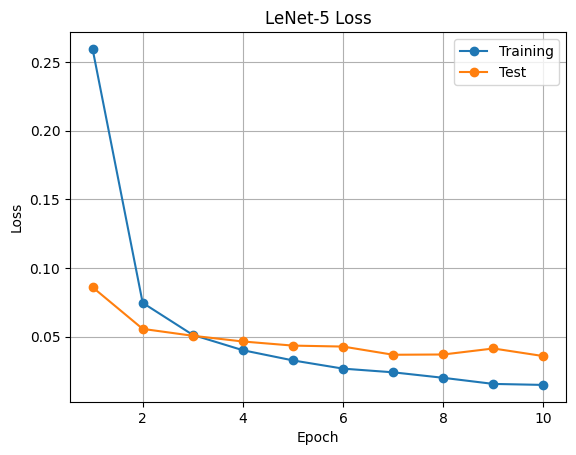

In [18]:
plt.plot(range(1, epochs + 1), train_losses_lenet, marker='o', label='Training')
plt.plot(range(1, epochs + 1), test_losses_lenet, marker='o', label='Test')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('LeNet-5 Loss')
plt.legend()
plt.grid(True)
plt.show()

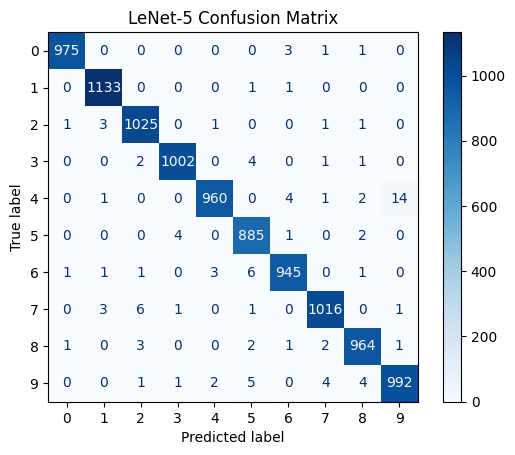

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model_lenet.eval()
y_true_lenet = []
y_pred_lenet = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)

        outputs = model_lenet(inputs)
        predictions = outputs.argmax(dim=1)

        y_true_lenet.extend(labels.numpy())
        y_pred_lenet.extend(predictions.cpu().numpy())

cm_lenet = confusion_matrix(y_true_lenet, y_pred_lenet)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lenet,
    display_labels=range(10)
).plot(cmap='Blues', values_format='d')

plt.title('LeNet-5 Confusion Matrix')
plt.show()

In [20]:
print(f"LeNet-5 Training Accuracy: {train_accs_lenet[-1]:.2f}%")
print(f"LeNet-5 Test Accuracy: {test_accs_lenet[-1]:.2f}%")

LeNet-5 Training Accuracy: 99.55%
LeNet-5 Test Accuracy: 98.97%


In [10]:
# 1. Define Modern CNN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ModernCNN(nn.Module):
    def __init__(self):
        super(ModernCNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.5)

        self.fc1 = nn.Linear(128 * 3 * 3, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [11]:
model_cnn = ModernCNN().to(device)

criterion_cnn = nn.CrossEntropyLoss()
optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=0.001)

epochs = 10

In [12]:
# 2. Training Loop

import torch.nn.functional as F

train_losses_cnn = []
test_losses_cnn = []
train_accs_cnn = []
test_accs_cnn = []

for epoch in range(epochs):
    model_cnn.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer_cnn.zero_grad()

        outputs = model_cnn(inputs)
        loss = criterion_cnn(outputs, labels)

        loss.backward()
        optimizer_cnn.step()

        running_loss += loss.item() * inputs.size(0)
        predicted = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    model_cnn.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model_cnn(inputs)
            loss = criterion_cnn(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            predicted = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss /= total
    test_acc = 100 * correct / total

    train_losses_cnn.append(train_loss)
    test_losses_cnn.append(test_loss)
    train_accs_cnn.append(train_acc)
    test_accs_cnn.append(test_acc)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch 1/10 | Train Loss: 0.1697 | Train Acc: 95.03% | Test Loss: 0.0363 | Test Acc: 98.81%
Epoch 2/10 | Train Loss: 0.0680 | Train Acc: 98.08% | Test Loss: 0.0272 | Test Acc: 99.17%
Epoch 3/10 | Train Loss: 0.0518 | Train Acc: 98.50% | Test Loss: 0.0240 | Test Acc: 99.29%
Epoch 4/10 | Train Loss: 0.0438 | Train Acc: 98.77% | Test Loss: 0.0254 | Test Acc: 99.26%
Epoch 5/10 | Train Loss: 0.0351 | Train Acc: 99.00% | Test Loss: 0.0225 | Test Acc: 99.32%
Epoch 6/10 | Train Loss: 0.0297 | Train Acc: 99.12% | Test Loss: 0.0300 | Test Acc: 99.18%
Epoch 7/10 | Train Loss: 0.0250 | Train Acc: 99.24% | Test Loss: 0.0250 | Test Acc: 99.28%
Epoch 8/10 | Train Loss: 0.0230 | Train Acc: 99.28% | Test Loss: 0.0213 | Test Acc: 99.46%
Epoch 9/10 | Train Loss: 0.0191 | Train Acc: 99.40% | Test Loss: 0.0317 | Test Acc: 99.26%
Epoch 10/10 | Train Loss: 0.0186 | Train Acc: 99.40% | Test Loss: 0.0247 | Test Acc: 99.35%


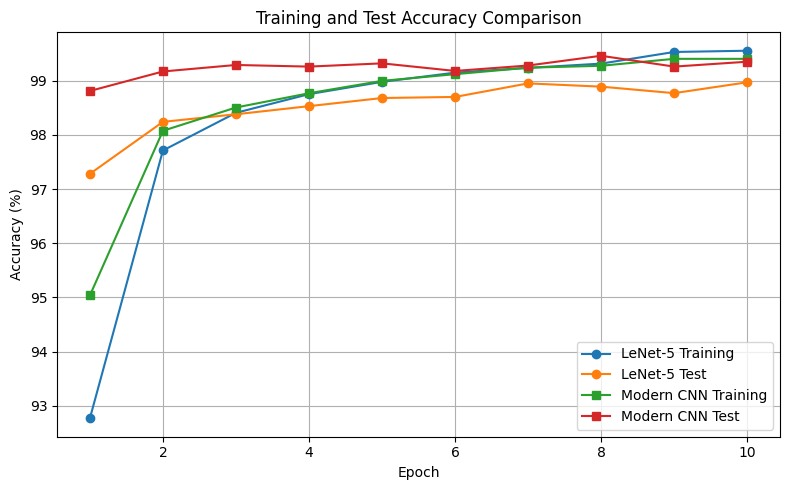

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, epochs + 1), train_accs_lenet, marker='o', label='LeNet-5 Training')
plt.plot(range(1, epochs + 1), test_accs_lenet, marker='o', label='LeNet-5 Test')
plt.plot(range(1, epochs + 1), train_accs_cnn, marker='s', label='Modern CNN Training')
plt.plot(range(1, epochs + 1), test_accs_cnn, marker='s', label='Modern CNN Test')

plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training and Test Accuracy Comparison')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

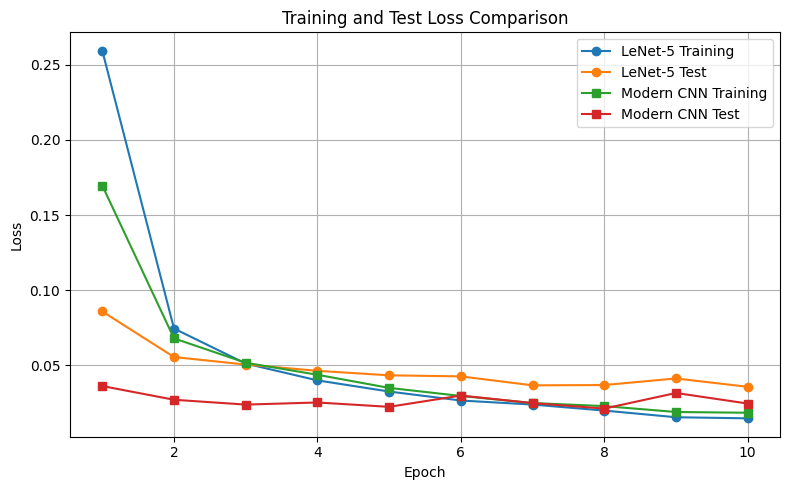

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, epochs + 1), train_losses_lenet, marker='o', label='LeNet-5 Training')
plt.plot(range(1, epochs + 1), test_losses_lenet, marker='o', label='LeNet-5 Test')
plt.plot(range(1, epochs + 1), train_losses_cnn, marker='s', label='Modern CNN Training')
plt.plot(range(1, epochs + 1), test_losses_cnn, marker='s', label='Modern CNN Test')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Test Loss Comparison')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

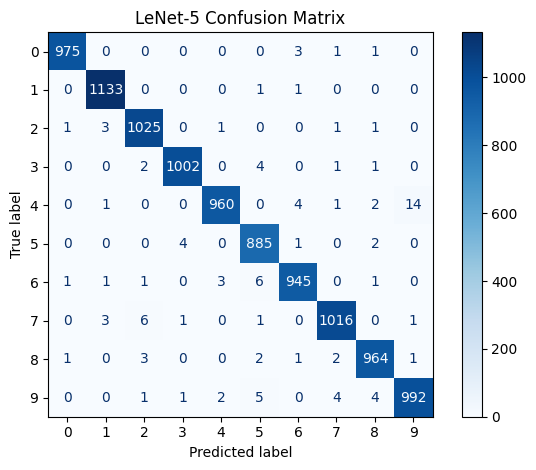

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model_lenet.eval()
y_true_lenet = []
y_pred_lenet = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)
        outputs = model_lenet(inputs)

        y_true_lenet.extend(labels.numpy())
        y_pred_lenet.extend(outputs.argmax(dim=1).cpu().numpy())

cm_lenet = confusion_matrix(y_true_lenet, y_pred_lenet)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lenet,
    display_labels=range(10)
).plot(cmap='Blues', values_format='d')

plt.title('LeNet-5 Confusion Matrix')
plt.tight_layout()
plt.show()

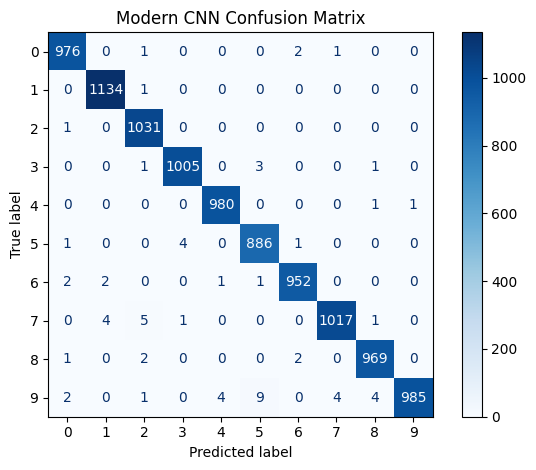

In [24]:
model_cnn.eval()
y_true_cnn = []
y_pred_cnn = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)
        outputs = model_cnn(inputs)

        y_true_cnn.extend(labels.numpy())
        y_pred_cnn.extend(outputs.argmax(dim=1).cpu().numpy())

cm_cnn = confusion_matrix(y_true_cnn, y_pred_cnn)

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=range(10)
).plot(cmap='Blues', values_format='d')

plt.title('Modern CNN Confusion Matrix')
plt.tight_layout()
plt.show()

In [25]:
print(f"LeNet-5 Training Accuracy: {train_accs_lenet[-1]:.2f}%")
print(f"LeNet-5 Test Accuracy: {test_accs_lenet[-1]:.2f}%")
print(f"Modern CNN Training Accuracy: {train_accs_cnn[-1]:.2f}%")
print(f"Modern CNN Test Accuracy: {test_accs_cnn[-1]:.2f}%")

LeNet-5 Training Accuracy: 99.55%
LeNet-5 Test Accuracy: 98.97%
Modern CNN Training Accuracy: 99.40%
Modern CNN Test Accuracy: 99.35%
